In [6]:
import numpy as np 
import matplotlib.pyplot as plt
import torch
import pandas as pd

In [7]:
v = np.loadtxt('v.csv', delimiter=',', skiprows=0)
s_diag = np.loadtxt('s.csv', delimiter=',', skiprows=0)
u = np.loadtxt('u.csv', delimiter=',', skiprows=0)
s = np.diag(s_diag)

In [8]:
# convert into numpy array

v_tensor = torch.from_numpy(v)
print("v_tensor: ", v_tensor)   
u_tensor = torch.from_numpy(u) 
print("u_tensor: ", u_tensor)   
s_tensor = torch.from_numpy(s)
print("s_tensor: ", s_tensor)


v_tensor:  tensor([[ 0.0245,  0.0244,  0.0244,  ...,  0.0370,  0.0372,  0.0380],
        [ 0.0232,  0.0227,  0.0223,  ...,  0.0256,  0.0265,  0.0262],
        [-0.0375, -0.0376, -0.0368,  ..., -0.0268, -0.0351, -0.0478],
        ...,
        [ 0.0223, -0.0596,  0.0330,  ..., -0.0715,  0.0702, -0.0019],
        [-0.0175,  0.0402,  0.0227,  ...,  0.1793, -0.1102,  0.0228],
        [-0.0337,  0.1493, -0.0315,  ..., -0.0922,  0.0814, -0.0231]],
       dtype=torch.float64)
u_tensor:  tensor([[ 0.0377,  0.0077, -0.0968,  ...,  0.0119,  0.0254,  0.0027],
        [ 0.0368,  0.0059, -0.0982,  ...,  0.0614,  0.0536, -0.0017],
        [ 0.0365,  0.0062, -0.0944,  ..., -0.1378, -0.0906,  0.0279],
        ...,
        [ 0.0912, -0.0410, -0.2123,  ...,  0.1171,  0.0115, -0.1033],
        [ 0.0925, -0.0372, -0.2212,  ..., -0.0675,  0.0075,  0.0775],
        [ 0.0939, -0.0329, -0.2257,  ...,  0.0165, -0.0022, -0.0197]],
       dtype=torch.float64)
s_tensor:  tensor([[2.8902e+04, 0.0000e+00, 0.0000e+00

In [9]:
def reconstruct(S, V, U, k):
    Sprime = S[0:k, 0:k]
    Uprime = U[:,0:k]
    Vprime = V[0:k, :]    #TODO: Please fix this to keep all columns but only the first k rows.
    return np.dot(np.dot(Uprime,Sprime),Vprime) #approximation of M

In [14]:
reconstructed_list = []
k_list = [0]
n_list=[0]
for k in range(4,24,2): #TODO: you can change this range (in a new code chunk)
    A = reconstruct(s_tensor, v_tensor, u_tensor,k) #reconstruct the image
    reconstructed_list.append(A)
    k_list.append(k)
n_images = len(reconstructed_list) #includes the original as the first one

C:\Users\munas\AppData\Local\Temp\ipykernel_14368\1474956710.py:5: DeprecationWarning: __array__ implementation doesn't accept a copy keyword, so passing copy=False failed. __array__ must implement 'dtype' and 'copy' keyword arguments. To learn more, see the migration guide https://numpy.org/devdocs/numpy_2_0_migration_guide.html#adapting-to-changes-in-the-copy-keyword
  return np.dot(np.dot(Uprime,Sprime),Vprime) #approximation of M


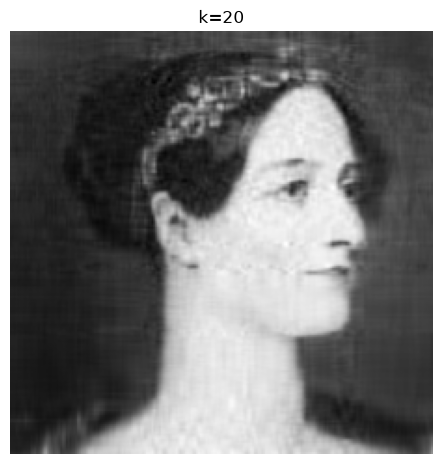

In [22]:
# reconstruction


plt.figure(figsize=(12, 12))
for k in range(len(reconstructed_list)):
    ax = plt.subplot(1,2,2)
    plt.axis('off') # turn off axis numbering
    plt.imshow(reconstructed_list[k], cmap=plt.cm.gray)
    if k>0:
      ax.set_title(f"k={k_list[k]}")
    if k==0: ax.set_title("Original")


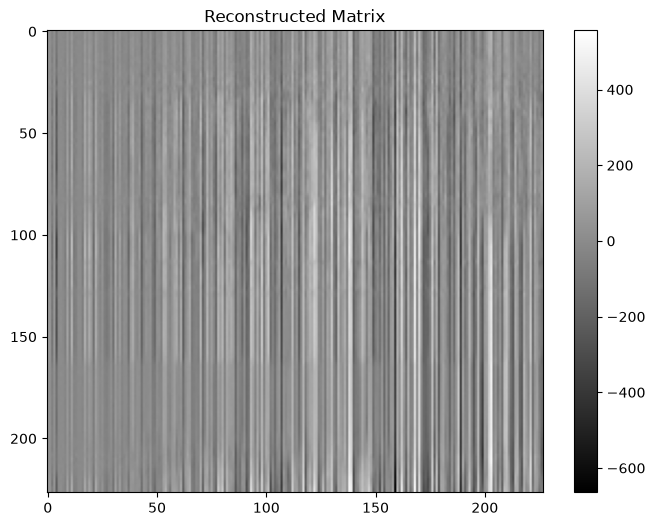